In [3]:
import sys
import os
from pathlib import Path

project_root = Path("/content/drive/MyDrive/CCTV_VLM_Project")

if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

os.chdir(project_root)

In [4]:
import cv2
import pandas as pd
from pathlib import Path

from src.config import VIDEOS_DIR

video_files = sorted([
    p for p in VIDEOS_DIR.iterdir()
    if p.suffix.lower() in [".mp4", ".avi", ".mov", ".mkv"]
])

print("Videos found:", len(video_files))

for video in video_files:
    print(video.name)

Videos found: 4
warehouse1.mp4
warehouse2.mp4
warehouse3.mp4
warehouse4.mp4


In [5]:
import cv2
import pandas as pd

metadata = []

for video in video_files:
    cap = cv2.VideoCapture(str(video))

    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration = frame_count / fps if fps > 0 else 0

    metadata.append({
        "video": video.name,
        "width": width,
        "height": height,
        "resolution": f"{width}x{height}",
        "fps": round(fps, 2),
        "frames": frame_count,
        "duration_sec": round(duration, 2),
        "aspect_ratio": round(width / height, 3) if height else None
    })

    cap.release()

metadata_df = pd.DataFrame(metadata)
display(metadata_df)

,video,width,height,resolution,fps,frames,duration_sec,aspect_ratio
0,warehouse1.mp4,1920,1080,1920x1080,24.83,198,7.97,1.778
1,warehouse2.mp4,1920,1080,1920x1080,24.80,173,6.98,1.778
2,warehouse3.mp4,1920,1080,1920x1080,24.83,198,7.97,1.778
3,warehouse4.mp4,1920,1080,1920x1080,24.80,173,6.98,1.778


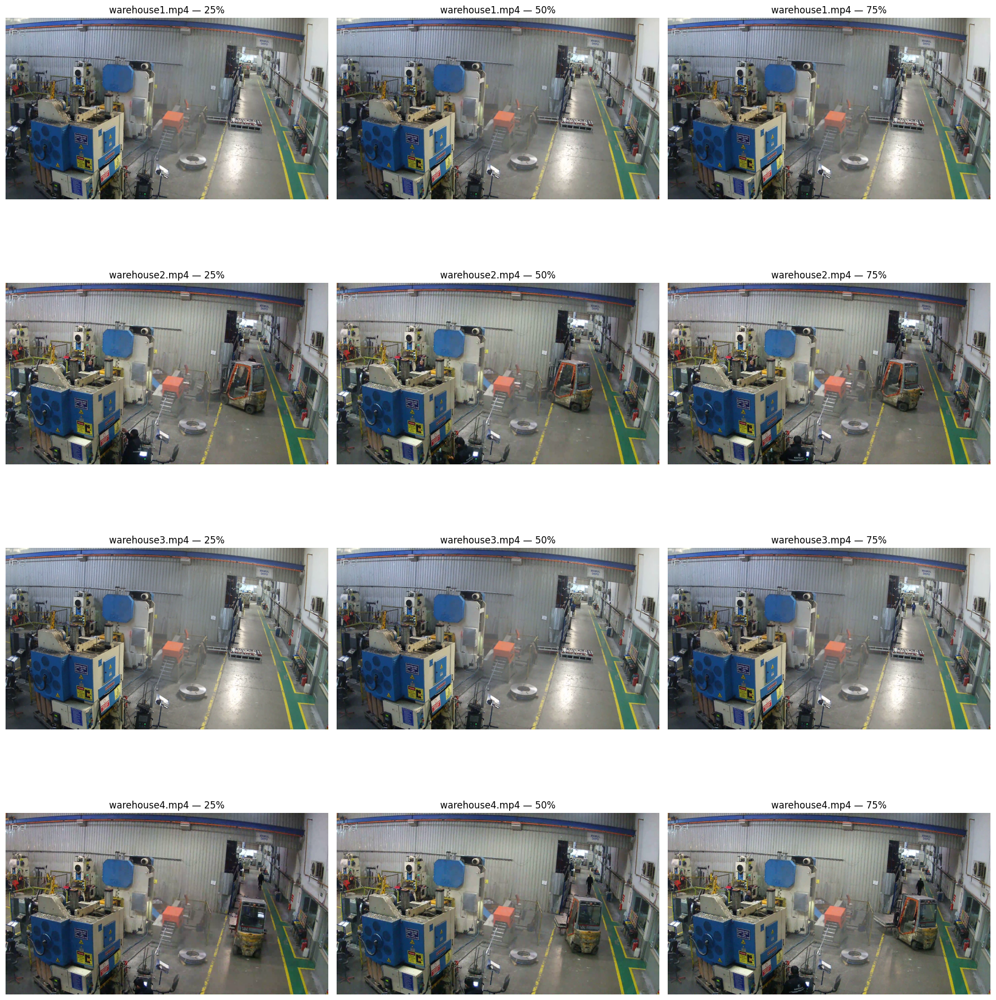

In [6]:
import cv2
import matplotlib.pyplot as plt

sample_frames = {}

for video in video_files:
    cap = cv2.VideoCapture(str(video))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    positions = {
        "25%": int(total_frames * 0.25),
        "50%": int(total_frames * 0.50),
        "75%": int(total_frames * 0.75)
    }

    frames = {}

    for label, frame_idx in positions.items():
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
        ret, frame = cap.read()

        if ret:
            frames[label] = cv2.cvtColor(
                frame, cv2.COLOR_BGR2RGB
            )

    sample_frames[video.name] = frames
    cap.release()

fig, axes = plt.subplots(4, 3, figsize=(18, 20))

for row, (video_name, frames) in enumerate(sample_frames.items()):
    for col, (label, frame) in enumerate(frames.items()):
        axes[row, col].imshow(frame)
        axes[row, col].set_title(f"{video_name} — {label}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [7]:
import cv2
import pandas as pd

reference_name = "warehouse1.mp4"

reference = cv2.cvtColor(
    sample_frames[reference_name]["50%"],
    cv2.COLOR_RGB2GRAY
)

orb = cv2.ORB_create(nfeatures = 3000)

kp_ref , des_ref = orb.detectAndCompute(reference , None)

bf = cv2.BFMatcher(cv2.NORM_HAMMING)

results = []

for video_name , frames in sample_frames.items():
    if video_name == reference_name:
        continue

    target = cv2.cvtColor(frames["50%"] , cv2.COLOR_RGB2GRAY)
    kp_target , des_target = orb.detectAndCompute(target , None)

    if des_ref is None or des_target is None:
        continue

    matches = bf.knnMatch(des_ref , des_target , k =2)

    good_matches = [
        m for m , n in matches
        if m.distance < 0.75 * n.distance
    ]

    inliers = 0
    inlier_ratio = 0.0

    if len(good_matches) >= 4:
        src_pts = [kp_ref[m.queryIdx].pt for m in good_matches]
        dst_pts = [kp_target[m.trainIdx].pt for m in good_matches]

        H, mask = cv2.findHomography(
            __import__("numpy").float32(src_pts).reshape(-1, 1, 2),
            __import__("numpy").float32(dst_pts).reshape(-1, 1, 2),
            cv2.RANSAC,
            5.0
        )

        if mask is not None:
            inliers = int(mask.sum())
            inlier_ratio = inliers / len(good_matches)

    results.append({
        "reference": reference_name,
        "comparison": video_name,
        "reference_keypoints": len(kp_ref),
        "comparison_keypoints": len(kp_target),
        "good_matches": len(good_matches),
        "homography_inliers": inliers,
        "inlier_ratio": round(inlier_ratio, 3)
    })

alignment_df = pd.DataFrame(results)
display(alignment_df)



,reference,comparison,reference_keypoints,comparison_keypoints,good_matches,homography_inliers,inlier_ratio
0,warehouse1.mp4,warehouse2.mp4,3000,3000,297,288,0.970
1,warehouse1.mp4,warehouse3.mp4,3000,3000,2028,2018,0.995
2,warehouse1.mp4,warehouse4.mp4,3000,3000,303,296,0.977


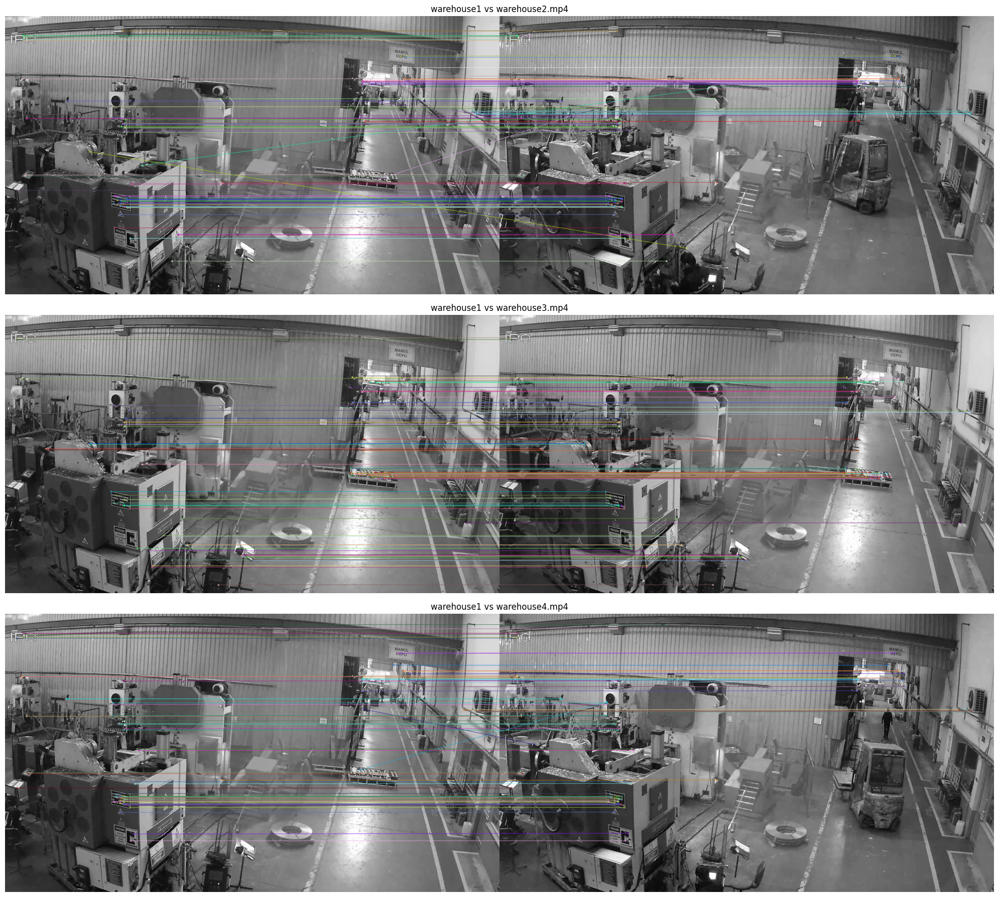

In [8]:
import cv2
import matplotlib.pyplot as plt

reference_name = "warehouse1.mp4"

reference = cv2.cvtColor(
    sample_frames[reference_name]["50%"],
    cv2.COLOR_RGB2GRAY
)

kp_ref, des_ref = orb.detectAndCompute(reference, None)

bf = cv2.BFMatcher(cv2.NORM_HAMMING)

comparison_names = [
    "warehouse2.mp4",
    "warehouse3.mp4",
    "warehouse4.mp4"
]

fig, axes = plt.subplots(3, 1, figsize=(20, 18))

for ax, video_name in zip(axes, comparison_names):

    target = cv2.cvtColor(
        sample_frames[video_name]["50%"],
        cv2.COLOR_RGB2GRAY
    )

    kp_target, des_target = orb.detectAndCompute(target, None)

    matches = bf.knnMatch(des_ref, des_target, k=2)

    good_matches = [
        m for m, n in matches
        if m.distance < 0.75 * n.distance
    ]

    visualization = cv2.drawMatches(
        reference,
        kp_ref,
        target,
        kp_target,
        good_matches[:100],
        None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    ax.imshow(visualization)
    ax.set_title(f"warehouse1 vs {video_name}")
    ax.axis("off")

plt.tight_layout()
plt.show()

Reference video: warehouse1.mp4
Frame index: 99
Frame dimensions: (1080, 1920, 3)


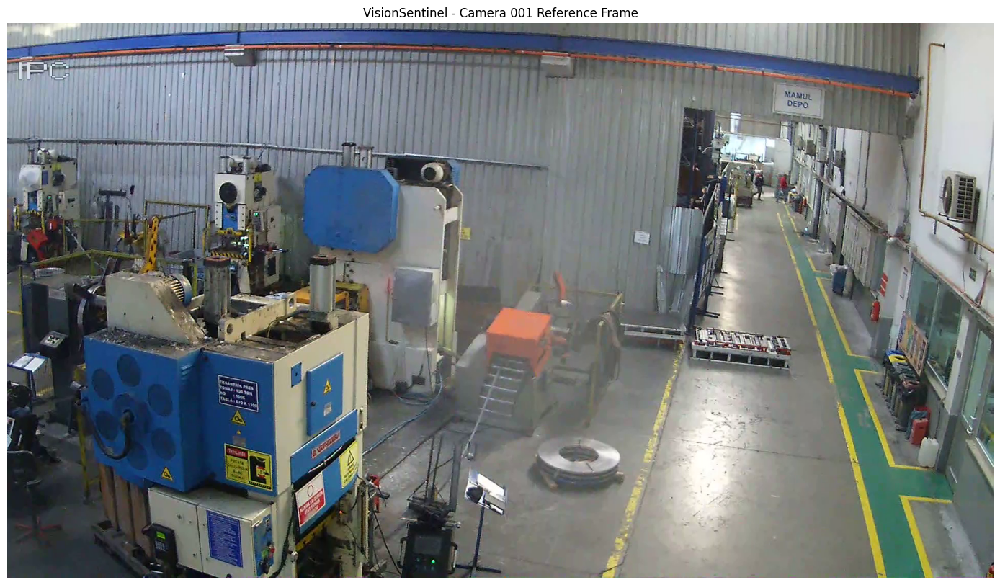

In [12]:
import cv2
import matplotlib.pyplot as plt


reference_video = VIDEOS_DIR /"camera001"/ "warehouse1.mp4"

cap = cv2.VideoCapture(str(reference_video))

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
reference_frame_idx = total_frames // 2

cap.set(cv2.CAP_PROP_POS_FRAMES, reference_frame_idx)

ret, reference_frame = cap.read()
cap.release()

if not ret:
    raise RuntimeError("Could not extract reference frame.")

reference_frame_rgb = cv2.cvtColor(
    reference_frame,
    cv2.COLOR_BGR2RGB
)

print("Reference video:", reference_video.name)
print("Frame index:", reference_frame_idx)
print("Frame dimensions:", reference_frame.shape)

plt.figure(figsize=(18, 10))
plt.imshow(reference_frame_rgb)
plt.title("VisionSentinel - Camera 001 Reference Frame")
plt.axis("off")
plt.show()

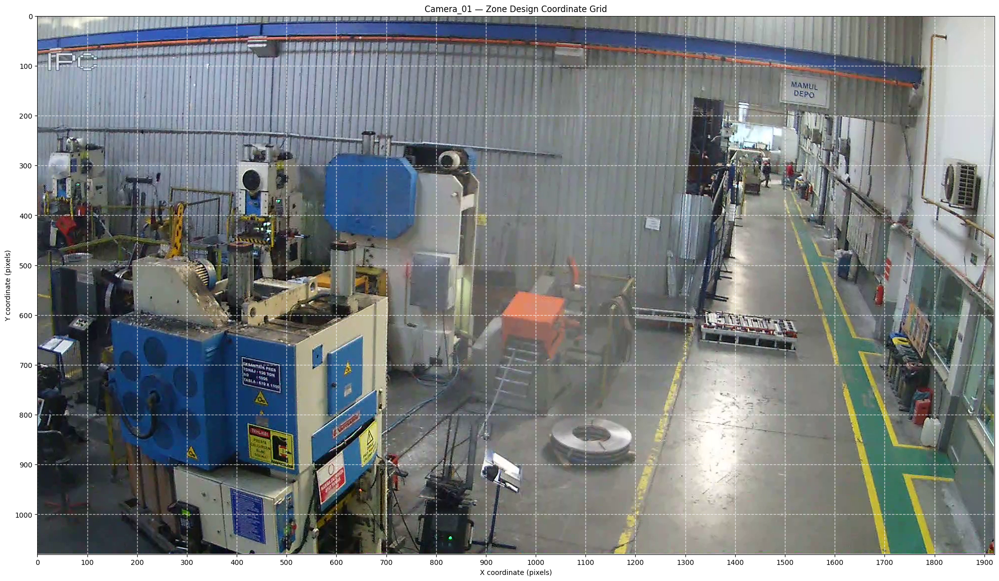

In [16]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(20, 12))

ax.imshow(reference_frame_rgb)

# Coordinate grid every 100 pixels
ax.set_xticks(np.arange(0, 1921, 100))
ax.set_yticks(np.arange(0, 1081, 100))

ax.grid(
    True,
    color="white",
    linestyle="--",
    linewidth=1.0,
    alpha=0.7
)

ax.set_xlim(0, 1920)
ax.set_ylim(1080, 0)

ax.set_xlabel("X coordinate (pixels)")
ax.set_ylabel("Y coordinate (pixels)")
ax.set_title("Camera_01 — Zone Design Coordinate Grid")

plt.tight_layout()
plt.show()